# Telco Satış Analitiği — Dijital ve Fiziksel Kanal Analizi

**Amaç:** 2021–2022 yıllarına ait aylık, şube bazlı satış verisiyle satış performansını analiz etmek, iyileşme alanlarını belirlemek ve 2023 Ocak ayı için ana ürün (Ürün1) ve çapraz ürün (Ürün2) satış adetlerini kanal bazında tahmin etmek.

**Veri (3 tablo):**
- **Satış:** Ürün1 için şube × ay bazında satış adedi, satış tutarı, müşteri uyruğu ve abonelik yaşı dağılımı
- **Çapraz Satış:** Ürün1 ile birlikte satılan Ürün2'nin satış adedi ile satıştan sonraki 5 gün ve 6–45 gün içindeki iptal adetleri
- **İlçe Demografi:** İlçe bazında nüfus, sosyo-ekonomik statü (SES), gelir, eğitim, çalışan ve emekli verileri

**Akış:**
1. Veriyi yükleme ve tanıma
2. Veri hazırlama (kanal tanımı, şube kodu eşleştirme, şehir isimleri, tarih)
3. Ciro ve satış adedi: nominal büyüme ile gerçek büyüme ayrımı
4. Şube ve uyruk analizi
5. Abonelik yaşı
6. Çapraz ürün iptal analizi
7. Demografi ve pazar penetrasyonu
8. 2023 Ocak tahmini (bonus)

## 1. Veriyi yükleme ve tanıma

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.holtwinters import ExponentialSmoothing

pd.set_option('display.float_format', lambda x: '%.2f' % x)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)

DOSYA = '../data/raw/telco_sales_analytics.xlsx'
GORSEL = '../images/'

satis = pd.read_excel(DOSYA, sheet_name='Satış')
capraz = pd.read_excel(DOSYA, sheet_name='Çapraz Satış')
demografi = pd.read_excel(DOSYA, sheet_name='İlçe Demografi')

for ad, df in [('SATIŞ', satis), ('ÇAPRAZ SATIŞ', capraz), ('İLÇE DEMOGRAFİ', demografi)]:
    print(f"=== {ad} ===")
    print("Boyut:", df.shape)
    print("Eksik değerler:")
    print(df.isnull().sum()[df.isnull().sum() > 0])
    print()

=== SATIŞ ===
Boyut: (43976, 10)
Eksik değerler:
Series([], dtype: int64)

=== ÇAPRAZ SATIŞ ===
Boyut: (21951, 8)
Eksik değerler:
CITY    21
dtype: int64

=== İLÇE DEMOGRAFİ ===
Boyut: (796, 20)
Eksik değerler:
Series([], dtype: int64)



In [2]:
print("=== SATIŞ describe (transpoze) ===")
satis.describe().T

=== SATIŞ describe (transpoze) ===


,count,mean,std,min,25%,50%,75%,max
DEALER_CODE,43976.00,791170.09,430564.59,11902.00,411962.00,814962.00,1164961.00,1489963.00
YEARMONTH,43976.00,202162.10,49.06,202104.00,202108.00,202202.00,202207.00,202212.00
URUNADET,43976.00,3546.69,91912.96,2.00,232.00,664.00,1414.00,4772526.00
URUNHACIM,43976.00,254750.21,7098021.62,11.98,15879.53,45005.88,95276.90,508128581.70
ABONE_YAS_0_3AY,43976.00,162.93,3072.21,0.00,16.00,46.00,92.00,166557.00
ABONE_YAS_4_12AY,43976.00,249.24,6018.13,0.00,17.00,54.00,116.00,383184.00
ABONE_YAS_1_3YAS,43976.00,411.27,10583.21,0.00,26.75,70.00,154.00,550367.00
ABONE_YAS_3_YAS,43976.00,584.83,16256.12,0.00,25.00,94.00,233.00,829913.00
ABONE,43976.00,1408.26,35759.31,1.00,94.00,281.00,600.00,1836078.00


## 2. Veri hazırlama

### 2.1 Dijital kanalı tanımlama
Satış tablosunda kanal bilgisi yok. En yüksek satış yapan şube kodlarına bakınca `720983` kodunun diğer şubelerden kat kat büyük olduğu ve her ay göründüğü görülüyor. Çapraz satış tablosunda `KANAL = DIJITAL` olan satırların kodu da bu şubeye karşılık geliyor. Bu nedenle `720983` dijital kanal, diğer tüm kodlar fiziksel şube olarak kabul edildi.

In [3]:
print("=== DEALER_CODE bazında toplam satış (en yüksek 10) ===")
print(satis.groupby('DEALER_CODE')['URUNADET'].sum().nlargest(10))

print("\nFarklı DEALER_CODE sayısı:", satis['DEALER_CODE'].nunique())
print("720983 kaç farklı ayda görünüyor:", satis[satis['DEALER_CODE']==720983]['YEARMONTH'].nunique(),
      "/", satis['YEARMONTH'].nunique())

=== DEALER_CODE bazında toplam satış (en yüksek 10) ===
DEALER_CODE
720983     106901900
1457962       471372
776961        422408
991961        347342
970961        328518
162961        220484
230965        218524
1138961       216744
530902        207254
22901         205668
Name: URUNADET, dtype: int64

Farklı DEALER_CODE sayısı: 1213
720983 kaç farklı ayda görünüyor: 21 / 21


In [4]:
DIJITAL_KOD = 720983

satis['KANAL_TIP'] = np.where(satis['DEALER_CODE']==DIJITAL_KOD, 'DIJITAL', 'FIZIKSEL')

# YEARMONTH'u (örn: 202104) gerçek bir tarihe çevir
satis['TARIH'] = pd.to_datetime(satis['YEARMONTH'].astype(str), format='%Y%m')

print(satis['KANAL_TIP'].value_counts())

KANAL_TIP
FIZIKSEL    43934
DIJITAL        42
Name: count, dtype: int64


### 2.2 Şube kodlarını eşleştirme
İki tablodaki şube kodları ilk denemede hiç eşleşmedi. Çapraz satış tablosundaki kodların, satış tablosundakilerin sonuna `0` eklenmiş hâli olduğu fark edildi (örneğin `7209830` → `720983`). Kodları 10'a bölünce eşleşme sağlandı. Bu düzeltme, şubelerin şehir bilgisini satış tablosuna taşımak için gerekli.

In [5]:
satis_kodlari = set(satis['DEALER_CODE'].unique())
capraz_kodlari = set(capraz['DEALER_CODE'].unique())
print("Düzeltme öncesi kesişen kod sayısı:", len(satis_kodlari & capraz_kodlari))

# Hipotez: Çapraz'daki her kod, Satış'takinin 10 katı mı?
print("Çapraz'daki kodların kaçı 0 ile bitiyor:", sum(k % 10 == 0 for k in capraz_kodlari), "/", len(capraz_kodlari))

capraz['DEALER_CODE'] = capraz['DEALER_CODE'] // 10

print("Düzeltme sonrası kesişen kod sayısı:", len(satis_kodlari & set(capraz['DEALER_CODE'].unique())))
print("Dijital kanal kodu artık eşleşiyor mu:", capraz[capraz['KANAL']=='DIJITAL']['DEALER_CODE'].unique())

Düzeltme öncesi kesişen kod sayısı: 0
Çapraz'daki kodların kaçı 0 ile bitiyor: 1212 / 1212
Düzeltme sonrası kesişen kod sayısı: 1212
Dijital kanal kodu artık eşleşiyor mu: [720983]


### 2.3 Şehir isimleri, tarih ve iptal oranları
Çapraz satıştaki şehir isimleri demografi tablosundaki il isimleriyle karşılaştırıldı. Tek fark `Afyon` / `Afyonkarahisar` idi ve düzeltildi.

In [6]:
demografi_iller = set(demografi['IL'].unique())
print("Düzeltme öncesi eşleşmeyen şehirler:", set(capraz['CITY'].dropna().unique()) - demografi_iller)

capraz['CITY'] = capraz['CITY'].replace('Afyon', 'Afyonkarahisar')
print("Düzeltme sonrası eşleşmeyen şehirler:", set(capraz['CITY'].dropna().unique()) - demografi_iller)

capraz['TARIH'] = pd.to_datetime(capraz['AY'].astype(str), format='%Y%m')

capraz['iptal_orani_5gun'] = capraz['5GUNIPTAL'] / capraz['ÇAPRAZ ÜRÜN ADET']
capraz['iptal_orani_6_45gun'] = capraz['6-45GUNIPTAL'] / capraz['ÇAPRAZ ÜRÜN ADET']
capraz['toplam_iptal_orani'] = (capraz['5GUNIPTAL'] + capraz['6-45GUNIPTAL']) / capraz['ÇAPRAZ ÜRÜN ADET']

Düzeltme öncesi eşleşmeyen şehirler: {'Afyon'}
Düzeltme sonrası eşleşmeyen şehirler: set()


### 2.4 Demografiyi il seviyesine toplama
Satış ve çapraz satış verisinde ilçe bilgisi olmadığı için demografi il seviyesine toplandı. Nüfus gibi kişi sayıları **toplanarak**, gelir ve oran gibi değerler ise **ortalaması alınarak** birleştirildi; oranları toplamak anlamsız sonuç verirdi.

In [7]:
il_demografi = demografi.groupby('IL').agg({
    'NUFUS':'sum',
    'AB_SES_GRUBU_NUFUSU_(KISI)':'sum',
    'C_SES_GRUBU_NUFUSU_(KISI)':'sum',
    'DE_SES_GRUBU_NUFUSU_(KISI)':'sum',
    'TOPLAM_EMEKLI_(KISI)':'sum',
    'ORTALAMA_HANE_GELIRI_(TL_/_AY)':'mean',
    'HABERLESME_HARCAMASI_(TL_/_AY)':'mean',
    'BEYAZ_YAKALI_CALISAN_ORAN_(_YUZDE_%)':'mean',
    'ORTALAMA_EGITIM_SURESI_(YIL)':'mean'
}).reset_index()

capraz_demografi = capraz.merge(il_demografi, left_on='CITY', right_on='IL', how='left')
print("Birleştirme sonrası boyut:", capraz_demografi.shape, "| orijinal:", capraz.shape)
print("Fiziksel satırlarda eşleşmeyen il:", capraz_demografi.loc[capraz_demografi['KANAL']=='FIZIKSEL', 'NUFUS'].isnull().sum())

Birleştirme sonrası boyut: (21951, 22) | orijinal: (21951, 12)
Fiziksel satırlarda eşleşmeyen il: 0


In [8]:
# Temizlenmiş tabloları kaydet
satis.to_csv('../data/processed/satis_temiz.csv', index=False, encoding='utf-8-sig')
capraz.to_csv('../data/processed/capraz_temiz.csv', index=False, encoding='utf-8-sig')
il_demografi.to_csv('../data/processed/demografi_il.csv', index=False, encoding='utf-8-sig')
print("3 dosya kaydedildi.")

3 dosya kaydedildi.


## 3. Ciro ve satış adedi: nominal büyüme ile gerçek büyüme

Ciro (satış tutarı) zamanla hızla artıyor. Ama bu dönemde yüksek enflasyon olduğu için ciro artışı tek başına büyümeyi göstermez. Bu yüzden ciro, satış adedi ve ortalama birim fiyat birlikte incelendi.

In [9]:
dijital_toplam = satis.loc[satis['KANAL_TIP']=='DIJITAL', 'URUNHACIM'].sum()
fiziksel_toplam = satis.loc[satis['KANAL_TIP']=='FIZIKSEL', 'URUNHACIM'].sum()

print(f"Dijital kanal toplam ciro: {dijital_toplam:,.0f} TL")
print(f"Fiziksel şubeler toplam ciro: {fiziksel_toplam:,.0f} TL")
print(f"Dijital'in toplam ciro içindeki payı: %{100*dijital_toplam/(dijital_toplam+fiziksel_toplam):.1f}")

Dijital kanal toplam ciro: 7,874,349,812 TL
Fiziksel şubeler toplam ciro: 3,328,545,339 TL
Dijital'in toplam ciro içindeki payı: %70.3


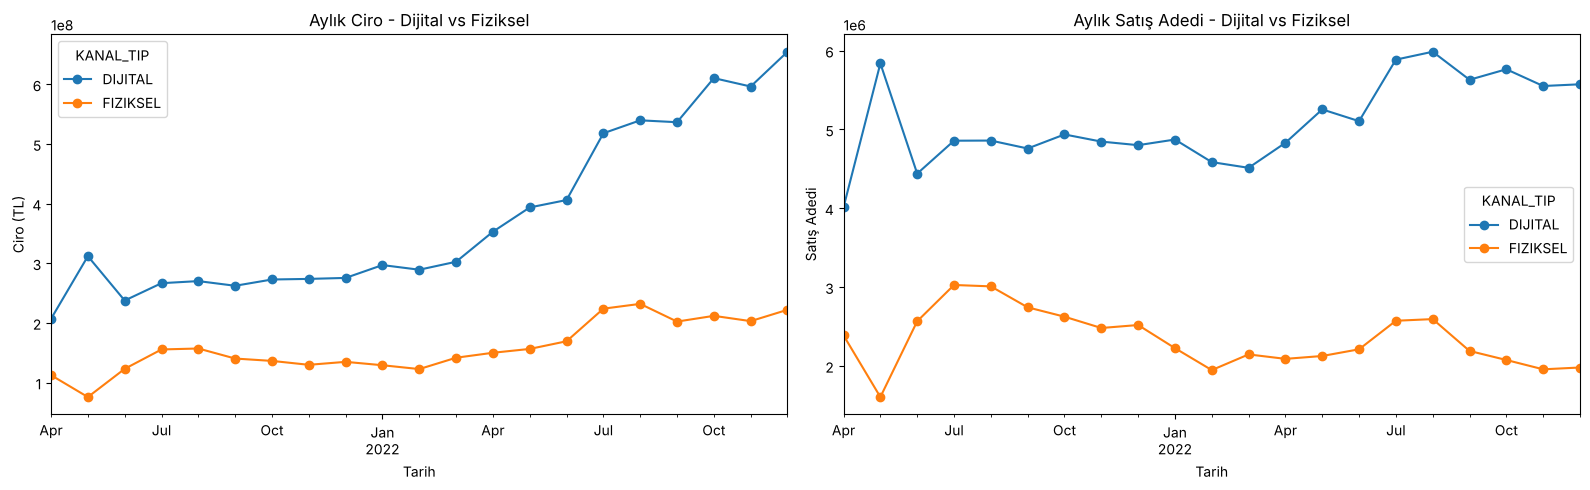

In [10]:
aylik_kanal_ciro = satis.groupby(['TARIH','KANAL_TIP'])['URUNHACIM'].sum().unstack()
aylik_kanal_adet = satis.groupby(['TARIH','KANAL_TIP'])['URUNADET'].sum().unstack()

fig, axes = plt.subplots(1, 2, figsize=(16,5))
aylik_kanal_ciro.plot(ax=axes[0], marker='o', title='Aylık Ciro - Dijital vs Fiziksel')
axes[0].set_ylabel('Ciro (TL)')
aylik_kanal_adet.plot(ax=axes[1], marker='o', title='Aylık Satış Adedi - Dijital vs Fiziksel')
axes[1].set_ylabel('Satış Adedi')
for ax in axes:
    ax.set_xlabel('Tarih')
plt.tight_layout()
plt.savefig(GORSEL + 'aylik_ciro_ve_adet.png')
plt.show()

In [11]:
# İlk ay ile son ay karşılaştırması: ciro ne kadar arttı, adet ne kadar arttı?
toplam_ciro = aylik_kanal_ciro.sum(axis=1)
toplam_adet = aylik_kanal_adet.sum(axis=1)

def degisim(seri):
    return 100 * (seri.iloc[-1] - seri.iloc[0]) / seri.iloc[0]

print(f"Toplam ciro değişimi: %{degisim(toplam_ciro):.1f}")
print(f"Toplam adet değişimi: %{degisim(toplam_adet):.1f}")
print()
for kanal in ['DIJITAL', 'FIZIKSEL']:
    print(f"{kanal:9s} -> ciro: %{degisim(aylik_kanal_ciro[kanal]):.1f} | adet: %{degisim(aylik_kanal_adet[kanal]):.1f}")

Toplam ciro değişimi: %174.6
Toplam adet değişimi: %18.0

DIJITAL   -> ciro: %216.4 | adet: %38.9
FIZIKSEL  -> ciro: %97.5 | adet: %-17.1


In [12]:
# Tek tek aylardaki dalgalanmaların etkisini azaltmak için lineer trend çizgisi üzerinden değişim
for kanal in ['DIJITAL', 'FIZIKSEL']:
    x = np.arange(len(aylik_kanal_adet))
    y = aylik_kanal_adet[kanal].values
    egim, kesisim = np.polyfit(x, y, 1)

    baslangic_tahmini = kesisim
    bitis_tahmini = egim * (len(x)-1) + kesisim
    trend_degisim_yuzde = 100 * (bitis_tahmini - baslangic_tahmini) / baslangic_tahmini

    print(f"=== {kanal} ===")
    print(f"Aylık ortalama değişim (eğim): {egim:,.0f} adet")
    print(f"Trend çizgisine göre toplam değişim: %{trend_degisim_yuzde:.1f}")
    print(f"Yön: {'ARTIŞ' if egim > 0 else 'AZALIŞ'}")
    print()

=== DIJITAL ===
Aylık ortalama değişim (eğim): 55,877 adet
Trend çizgisine göre toplam değişim: %24.7
Yön: ARTIŞ

=== FIZIKSEL ===
Aylık ortalama değişim (eğim): -22,991 adet
Trend çizgisine göre toplam değişim: %-17.9
Yön: AZALIŞ



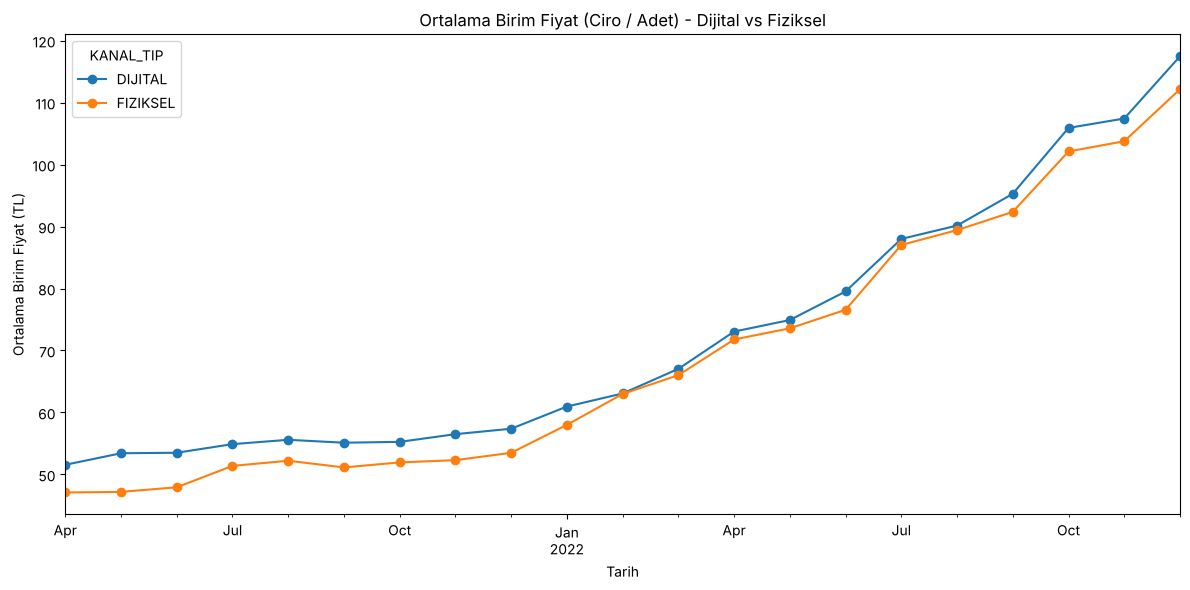

In [13]:
birim_fiyat = aylik_kanal_ciro / aylik_kanal_adet

birim_fiyat.plot(kind='line', figsize=(12,6), marker='o',
                 title='Ortalama Birim Fiyat (Ciro / Adet) - Dijital vs Fiziksel')
plt.xlabel('Tarih')
plt.ylabel('Ortalama Birim Fiyat (TL)')
plt.tight_layout()
plt.savefig(GORSEL + 'birim_fiyat_trend.png')
plt.show()

**Bulgu:** Ciro artışının büyük kısmı birim fiyat artışından (enflasyondan) geliyor. Dijital kanalda ciro ilk aydan son aya %216 artarken adet %39 artıyor; yani büyümenin bir kısmı gerçek. Fiziksel kanalda ciro %97.5 artarken adet trendi %17.9 düşüyor: kanal küçülüyor ve fiyat artışı bunu ciro rakamlarında gizliyor. Sadece ciroya bakıp "iki kanal da büyüyor" demek yanıltıcı olur.

## 4. Şube ve uyruk analizi

In [14]:
sube_performans = satis[satis['KANAL_TIP']=='FIZIKSEL'].groupby('DEALER_CODE').agg({
    'URUNHACIM':'sum',
    'URUNADET':'sum',
    'ABONE':'sum'
}).sort_values('URUNHACIM', ascending=False)

print("=== En İyi 10 Şube (Ciro Bazında) ===")
print(sube_performans.head(10))
print("\n=== Genel İstatistik ===")
print(sube_performans['URUNHACIM'].describe())

ilk_yuzde10 = sube_performans['URUNHACIM'].head(int(len(sube_performans)*0.1)).sum()
print(f"\nEn büyük %10 şubenin fiziksel ciro içindeki payı: %{100*ilk_yuzde10/sube_performans['URUNHACIM'].sum():.1f}")

=== En İyi 10 Şube (Ciro Bazında) ===
              URUNHACIM  URUNADET   ABONE
DEALER_CODE                              
1457962     38172284.10    471372  212592
776961      37127862.10    422408  191336
991961      22578120.84    347342  130945
1326961     22068362.52    162142   76631
970961      17738171.62    328518   84154
230965      17264277.58    218524   86548
1138961     16254878.38    216744   82667
162961      16077395.54    220484   86342
22901       15514141.36    205668   81174
530902      15302050.84    207254   87809

=== Genel İstatistik ===
count       1212.00
mean     2746324.54
std      2874665.34
min        12532.00
25%      1147751.35
50%      1985058.23
75%      3433797.65
max     38172284.10
Name: URUNHACIM, dtype: float64

En büyük %10 şubenin fiziksel ciro içindeki payı: %32.7


In [15]:
uyruk_karsilastirma = satis.groupby('NATIONALITY').agg({
    'URUNHACIM':'sum',
    'URUNADET':'sum',
    'ABONE':'sum'
})
uyruk_karsilastirma['ortalama_birim_fiyat'] = uyruk_karsilastirma['URUNHACIM'] / uyruk_karsilastirma['URUNADET']
uyruk_karsilastirma['musteri_basi_ciro'] = uyruk_karsilastirma['URUNHACIM'] / uyruk_karsilastirma['ABONE']
uyruk_karsilastirma

,URUNHACIM,URUNADET,ABONE,ortalama_birim_fiyat,musteri_basi_ciro
NATIONALITY,,,,,
OTHER,2583715284.48,32992568,13198995,78.31,195.75
TURK,8619179866.14,122976786,48730797,70.09,176.87


NATIONALITY
OTHER   165.89
TURK    138.66
Name: musteri_basi_ciro, dtype: float64

Yabancı uyruklu müşteriler müşteri başına daha fazla harcıyor: toplam üzerinden %10.7, şube-ay medyanı üzerinden %19.6


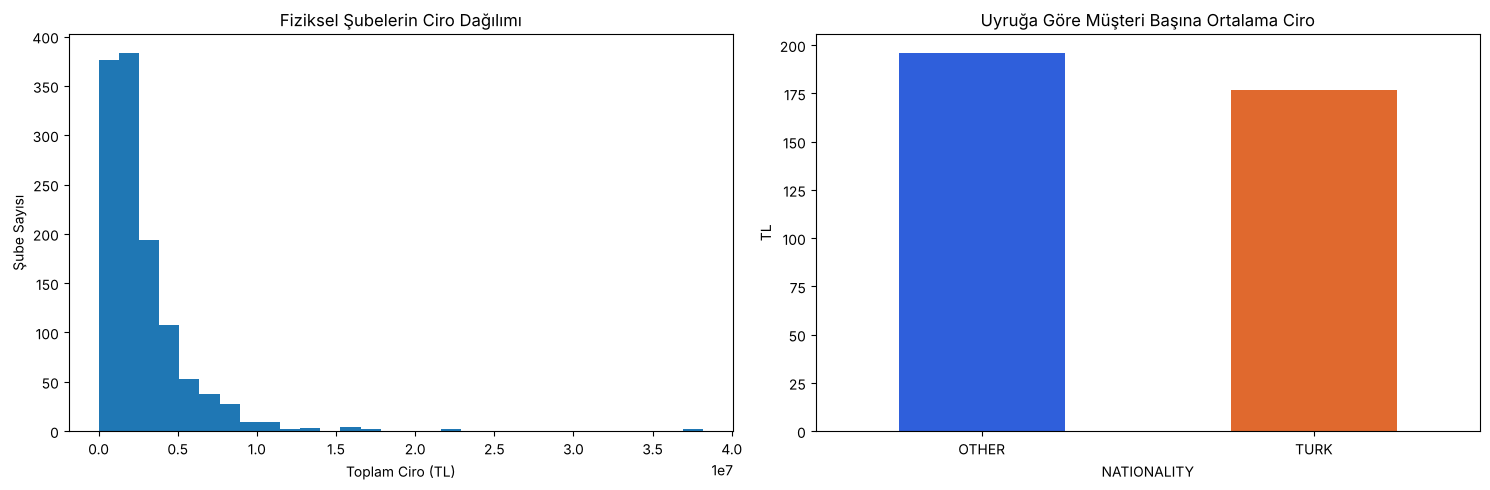

In [16]:
# Toplam üzerinden oran, en büyük şube (dijital kanal) tarafından domine ediliyor.
# Bu yüzden şube × ay satırı bazında müşteri başı ciro da hesaplandı ve medyanı karşılaştırıldı.
satis['musteri_basi_ciro'] = satis['URUNHACIM'] / satis['ABONE']
satir_bazli = satis.groupby('NATIONALITY')['musteri_basi_ciro'].median()
print(satir_bazli)

fark_toplam = 100 * (uyruk_karsilastirma.loc['OTHER','musteri_basi_ciro'] / uyruk_karsilastirma.loc['TURK','musteri_basi_ciro'] - 1)
fark_medyan = 100 * (satir_bazli['OTHER'] / satir_bazli['TURK'] - 1)
print(f"\nYabancı uyruklu müşteriler müşteri başına daha fazla harcıyor: "
      f"toplam üzerinden %{fark_toplam:.1f}, şube-ay medyanı üzerinden %{fark_medyan:.1f}")

fig, axes = plt.subplots(1, 2, figsize=(15,5))
axes[0].hist(sube_performans['URUNHACIM'], bins=30)
axes[0].set_title('Fiziksel Şubelerin Ciro Dağılımı')
axes[0].set_xlabel('Toplam Ciro (TL)')
axes[0].set_ylabel('Şube Sayısı')

uyruk_karsilastirma['musteri_basi_ciro'].plot(kind='bar', ax=axes[1], color=['#2f5fdb','#e0692e'])
axes[1].set_title('Uyruğa Göre Müşteri Başına Ortalama Ciro')
axes[1].set_ylabel('TL')
axes[1].tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.savefig(GORSEL + 'sube_ve_uyruk.png')
plt.show()

**Bulgu:** Fiziksel şubelerin cirosu çok eşitsiz dağılmış. Şubelerin çoğu düşük ciro yaparken birkaç şube milyonlarca TL üretiyor, bu da gelirin az sayıda "yıldız şubeye" bağımlı olduğunu gösteriyor. Yabancı uyruklu müşteriler müşteri başına daha fazla harcıyor; ayrı bir segment stratejisi değerlendirilebilir.

## 5. Abonelik yaşı

=== Yüzdesel Dağılım ===
ABONE_YAS_0_3AY    11.57
ABONE_YAS_4_12AY   17.70
ABONE_YAS_1_3YAS   29.20
ABONE_YAS_3_YAS    41.53
dtype: float64

=== Kanal Bazında Abonelik Yaşı Dağılımı (%) ===
           ABONE_YAS_0_3AY  ABONE_YAS_4_12AY  ABONE_YAS_1_3YAS  \
KANAL_TIP                                                        
DIJITAL               9.15             16.85             30.44   
FIZIKSEL             16.58             19.44             26.65   

           ABONE_YAS_3_YAS  
KANAL_TIP                   
DIJITAL              43.56  
FIZIKSEL             37.33  


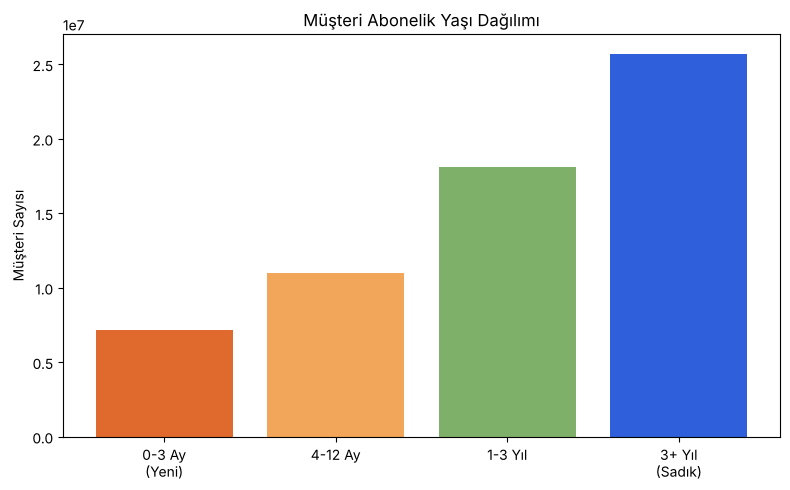

In [17]:
yas_kolonlari = ['ABONE_YAS_0_3AY','ABONE_YAS_4_12AY','ABONE_YAS_1_3YAS','ABONE_YAS_3_YAS']
yas_toplam = satis[yas_kolonlari].sum()
yas_yuzde = 100 * yas_toplam / yas_toplam.sum()
print("=== Yüzdesel Dağılım ===")
print(yas_yuzde)

print("\n=== Kanal Bazında Abonelik Yaşı Dağılımı (%) ===")
kanal_yas = satis.groupby('KANAL_TIP')[yas_kolonlari].sum()
print(kanal_yas.div(kanal_yas.sum(axis=1), axis=0) * 100)

etiketler = ['0-3 Ay\n(Yeni)', '4-12 Ay', '1-3 Yıl', '3+ Yıl\n(Sadık)']
plt.figure(figsize=(8,5))
plt.bar(etiketler, yas_toplam.values, color=['#e0692e','#f2a65a','#7fb069','#2f5fdb'])
plt.title('Müşteri Abonelik Yaşı Dağılımı')
plt.ylabel('Müşteri Sayısı')
plt.tight_layout()
plt.savefig(GORSEL + 'abonelik_yasi_dagilimi.png')
plt.show()

**Bulgu:** Müşteri tabanının büyük kısmı 3 yılı aşkın süredir abone olan sadık müşterilerden oluşuyor; yeni müşterilerin (0–3 ay) payı küçük. Ana ürünü alan müşteriler sadık, ama aşağıda görüleceği gibi çapraz satılan üründe iptaller yüksek. Bu, sorunun genel hizmet kalitesinde değil, çapraz satış sürecinde olduğunu gösteriyor.

## 6. Çapraz ürün (Ürün2) iptal analizi

In [18]:
genel_5gun = capraz['5GUNIPTAL'].sum() / capraz['ÇAPRAZ ÜRÜN ADET'].sum()
genel_6_45gun = capraz['6-45GUNIPTAL'].sum() / capraz['ÇAPRAZ ÜRÜN ADET'].sum()
print(f"Genel toplam iptal oranı: %{(genel_5gun+genel_6_45gun)*100:.2f}\n")

kanal_ozet = capraz.groupby('KANAL').agg({
    'ÇAPRAZ ÜRÜN ADET':'sum',
    '5GUNIPTAL':'sum',
    '6-45GUNIPTAL':'sum'
})
kanal_ozet['iptal_5gun_%'] = 100 * kanal_ozet['5GUNIPTAL'] / kanal_ozet['ÇAPRAZ ÜRÜN ADET']
kanal_ozet['iptal_6_45gun_%'] = 100 * kanal_ozet['6-45GUNIPTAL'] / kanal_ozet['ÇAPRAZ ÜRÜN ADET']
kanal_ozet['toplam_iptal_%'] = kanal_ozet['iptal_5gun_%'] + kanal_ozet['iptal_6_45gun_%']
kanal_ozet

Genel toplam iptal oranı: %24.25



,ÇAPRAZ ÜRÜN ADET,5GUNIPTAL,6-45GUNIPTAL,iptal_5gun_%,iptal_6_45gun_%,toplam_iptal_%
KANAL,,,,,,
DIJITAL,757654,1226,34460,0.16,4.55,4.71
FIZIKSEL,3056582,52326,837002,1.71,27.38,29.10


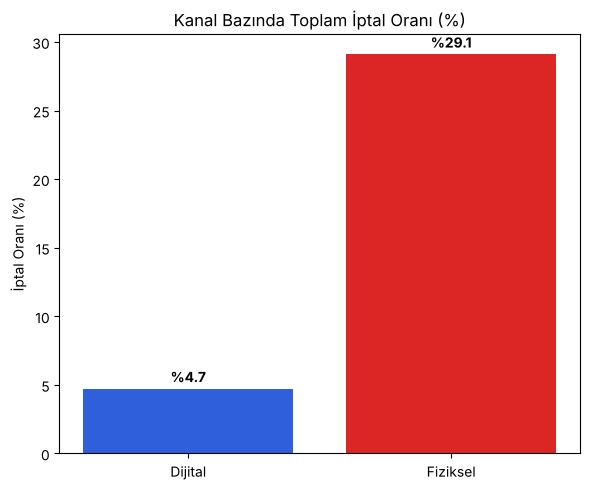

In [19]:
plt.figure(figsize=(6,5))
bars = plt.bar(['Dijital', 'Fiziksel'], kanal_ozet['toplam_iptal_%'], color=['#2f5fdb','#dc2626'])
plt.title('Kanal Bazında Toplam İptal Oranı (%)')
plt.ylabel('İptal Oranı (%)')
for bar, oran in zip(bars, kanal_ozet['toplam_iptal_%']):
    plt.text(bar.get_x()+bar.get_width()/2, oran+0.5, f'%{oran:.1f}', ha='center', fontweight='bold')
plt.tight_layout()
plt.savefig(GORSEL + 'kanal_iptal_karsilastirma.png')
plt.show()

Fiziksel kanaldaki iptallerin çoğu 6–45 gün aralığında. Bu, sorunun sadece "anlık pişmanlık" olmadığını, müşterinin ürünü kullandıktan sonra memnun kalmadığını da gösteriyor. Olası kök nedenler: satış sırasında yetersiz bilgilendirme, satış hedefi baskısıyla agresif satış, ürün–fiyat uyumsuzluğu.

### Coğrafi kırılım: şehir ve bölge

In [20]:
fiziksel = capraz[capraz['KANAL']=='FIZIKSEL'].copy()

sehir_iptal = fiziksel.groupby('CITY').agg({
    'ÇAPRAZ ÜRÜN ADET':'sum',
    '5GUNIPTAL':'sum',
    '6-45GUNIPTAL':'sum'
})
# Çok küçük hacimli şehirleri gürültü olarak elemek için minimum satış filtresi
sehir_iptal = sehir_iptal[sehir_iptal['ÇAPRAZ ÜRÜN ADET'] > 1000]
sehir_iptal['toplam_iptal_%'] = 100*(sehir_iptal['5GUNIPTAL']+sehir_iptal['6-45GUNIPTAL']) / sehir_iptal['ÇAPRAZ ÜRÜN ADET']
print("=== Fiziksel kanalda iptal oranı en yüksek 10 şehir ===")
sehir_iptal.sort_values('toplam_iptal_%', ascending=False).head(10)

=== Fiziksel kanalda iptal oranı en yüksek 10 şehir ===


,ÇAPRAZ ÜRÜN ADET,5GUNIPTAL,6-45GUNIPTAL,toplam_iptal_%
CITY,,,,
Balıkesir,45144,1314,17898,42.56
Tekirdağ,87560,1456,34766,41.37
Kahramanmaraş,84658,5088,29784,41.19
Kars,29150,178,11816,41.15
Samsun,69788,1200,26370,39.51
Kırklareli,13780,160,5146,38.51
Eskişehir,22128,310,7800,36.65
Edirne,18604,146,6666,36.62
Bursa,162220,1988,55336,35.34


In [21]:
print("=== Her bölgenin içerdiği şehirler ===")
for bolge, sehirler in fiziksel.groupby('BOLGE')['CITY'].unique().items():
    print(f"Bölge {bolge} ({len(sehirler)} şehir): {sorted(sehirler.tolist())[:8]} ...")

=== Her bölgenin içerdiği şehirler ===
Bölge 1 (9 şehir): ['Antalya', 'Aydın', 'Burdur', 'Denizli', 'Isparta', 'Manisa', 'Muğla', 'Uşak'] ...
Bölge 2 (12 şehir): ['Adana', 'Afyonkarahisar', 'Balıkesir', 'Bilecik', 'Bursa', 'Eskişehir', 'Hatay', 'Kütahya'] ...
Bölge 4 (4 şehir): ['Edirne', 'Kırklareli', 'Tekirdağ', 'İstanbul'] ...
Bölge 5 (26 şehir): ['Amasya', 'Ardahan', 'Artvin', 'Ağrı', 'Bartın', 'Bayburt', 'Düzce', 'Erzincan'] ...
Bölge 6 (18 şehir): ['Adıyaman', 'Batman', 'Bingöl', 'Bitlis', 'Diyarbakır', 'Elazığ', 'Gaziantep', 'Hakkari'] ...


                          toplam_iptal_%
BOLGE                                   
İstanbul / Trakya                  35.73
Güney Marmara / Çukurova           32.19
Karadeniz / Doğu Anadolu           25.90
Güneydoğu Anadolu                  23.36
Ege / Batı Akdeniz                 19.17


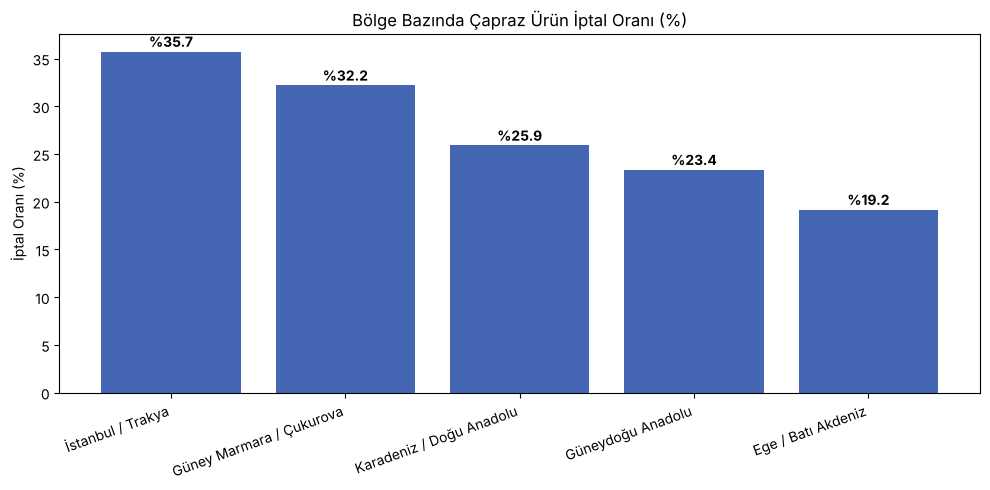

In [22]:
bolge_iptal = fiziksel.groupby('BOLGE').agg({
    'ÇAPRAZ ÜRÜN ADET':'sum',
    '5GUNIPTAL':'sum',
    '6-45GUNIPTAL':'sum'
})
bolge_iptal['toplam_iptal_%'] = 100*(bolge_iptal['5GUNIPTAL']+bolge_iptal['6-45GUNIPTAL']) / bolge_iptal['ÇAPRAZ ÜRÜN ADET']
bolge_iptal = bolge_iptal.sort_values('toplam_iptal_%', ascending=False)

# Bölge numaralarına, içerdikleri şehirlere bakılarak isim verildi
bolge_isimleri = {
    1: 'Ege / Batı Akdeniz',
    2: 'Güney Marmara / Çukurova',
    4: 'İstanbul / Trakya',
    5: 'Karadeniz / Doğu Anadolu',
    6: 'Güneydoğu Anadolu'
}
bolge_iptal.index = bolge_iptal.index.map(bolge_isimleri)
print(bolge_iptal[['toplam_iptal_%']])

plt.figure(figsize=(10,5))
bars = plt.bar(bolge_iptal.index, bolge_iptal['toplam_iptal_%'], color='#4566b2')
plt.title('Bölge Bazında Çapraz Ürün İptal Oranı (%)')
plt.ylabel('İptal Oranı (%)')
plt.xticks(rotation=20, ha='right')
for bar, oran in zip(bars, bolge_iptal['toplam_iptal_%']):
    plt.text(bar.get_x()+bar.get_width()/2, oran+0.5, f'%{oran:.1f}', ha='center', fontweight='bold')
plt.tight_layout()
plt.savefig(GORSEL + 'bolge_iptal.png')
plt.show()

### Zaman içinde iptal oranı ve satış adedi ile ilişkisi

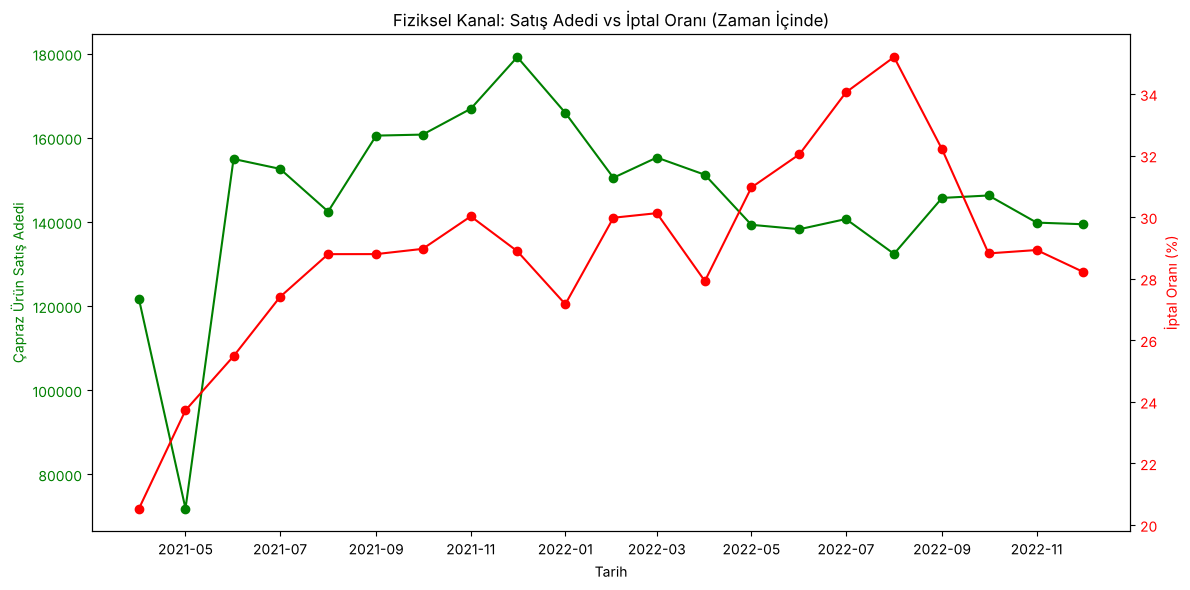

Satış adedi ile iptal oranı arasındaki korelasyon: 0.289


In [23]:
aylik_fiziksel = fiziksel.groupby('TARIH').agg({
    'ÇAPRAZ ÜRÜN ADET':'sum',
    '5GUNIPTAL':'sum',
    '6-45GUNIPTAL':'sum'
})
aylik_fiziksel['toplam_iptal_%'] = 100*(aylik_fiziksel['5GUNIPTAL']+aylik_fiziksel['6-45GUNIPTAL']) / aylik_fiziksel['ÇAPRAZ ÜRÜN ADET']

fig, ax1 = plt.subplots(figsize=(12,6))
ax1.plot(aylik_fiziksel.index, aylik_fiziksel['ÇAPRAZ ÜRÜN ADET'], color='green', marker='o')
ax1.set_xlabel('Tarih')
ax1.set_ylabel('Çapraz Ürün Satış Adedi', color='green')
ax1.tick_params(axis='y', labelcolor='green')

ax2 = ax1.twinx()
ax2.plot(aylik_fiziksel.index, aylik_fiziksel['toplam_iptal_%'], color='red', marker='o')
ax2.set_ylabel('İptal Oranı (%)', color='red')
ax2.tick_params(axis='y', labelcolor='red')

plt.title('Fiziksel Kanal: Satış Adedi vs İptal Oranı (Zaman İçinde)')
fig.tight_layout()
plt.savefig(GORSEL + 'satis_vs_iptal.png')
plt.show()

korelasyon = aylik_fiziksel['ÇAPRAZ ÜRÜN ADET'].corr(aylik_fiziksel['toplam_iptal_%'])
print(f"Satış adedi ile iptal oranı arasındaki korelasyon: {korelasyon:.3f}")

**Bulgu:** Fiziksel kanalda çapraz ürün iptal oranı dijitalin kat kat üzerinde ve iptallerin çoğu 6–45 gün aralığında. Bölgeler arasında belirgin fark var: İstanbul/Trakya bölgesi en yüksek iptal oranına sahip. Sorun coğrafi bir talep sorunundan çok bölge yönetimi ve satış ekibi pratiğiyle ilgili görünüyor.

## 7. Demografi ve pazar penetrasyonu

### 7.1 Demografi ile iptal oranı ilişkisi

In [24]:
il_ozet = capraz_demografi[capraz_demografi['KANAL']=='FIZIKSEL'].groupby('CITY').agg({
    'ÇAPRAZ ÜRÜN ADET':'sum',
    '5GUNIPTAL':'sum',
    '6-45GUNIPTAL':'sum',
    'ORTALAMA_HANE_GELIRI_(TL_/_AY)':'first',
    'HABERLESME_HARCAMASI_(TL_/_AY)':'first',
    'BEYAZ_YAKALI_CALISAN_ORAN_(_YUZDE_%)':'first',
    'ORTALAMA_EGITIM_SURESI_(YIL)':'first'
})
il_ozet = il_ozet[il_ozet['ÇAPRAZ ÜRÜN ADET'] > 1000]
il_ozet['iptal_orani_%'] = 100*(il_ozet['5GUNIPTAL']+il_ozet['6-45GUNIPTAL']) / il_ozet['ÇAPRAZ ÜRÜN ADET']

print("İptal oranının demografik değişkenlerle korelasyonu:")
il_ozet.drop(columns=['ÇAPRAZ ÜRÜN ADET','5GUNIPTAL','6-45GUNIPTAL']).corr()['iptal_orani_%'].drop('iptal_orani_%').round(3)

İptal oranının demografik değişkenlerle korelasyonu:


ORTALAMA_HANE_GELIRI_(TL_/_AY)         0.24
HABERLESME_HARCAMASI_(TL_/_AY)         0.16
BEYAZ_YAKALI_CALISAN_ORAN_(_YUZDE_%)   0.23
ORTALAMA_EGITIM_SURESI_(YIL)           0.18
Name: iptal_orani_%, dtype: float64

Korelasyonlar zayıf: iptal oranı ilin gelir, eğitim ya da çalışan profiliyle açıklanmıyor. Bu da iptallerin müşteri profilinden çok satış sürecinden kaynaklandığı yorumunu destekliyor.

### 7.2 İl bazında abone penetrasyonu
Satış tablosunda şehir bilgisi yok. Bölüm 2.2'de düzeltilen şube kodları sayesinde şubelerin şehri çapraz satış tablosundan alındı.

In [25]:
dealer_city_map = capraz[['DEALER_CODE','CITY']].dropna().drop_duplicates()
satis_city = satis.merge(dealer_city_map, on='DEALER_CODE', how='left')
print("Şehri bulunamayan fiziksel satış satırı:", satis_city.loc[satis_city['KANAL_TIP']=='FIZIKSEL', 'CITY'].isnull().sum(),
      "/", (satis_city['KANAL_TIP']=='FIZIKSEL').sum())

Şehri bulunamayan fiziksel satış satırı: 2 / 43934


In [26]:
# ABONE değerlerini aylar boyunca toplamak aynı müşteriyi tekrar tekrar sayar.
# Bu yüzden son ayın (Aralık 2022) değeri, o anki aktif müşteri sayısı olarak kullanıldı.
son_ay = satis_city[satis_city['YEARMONTH']==satis_city['YEARMONTH'].max()]
il_abone = son_ay.groupby('CITY')['ABONE'].sum().reset_index()

il_penetrasyon = il_abone.merge(il_demografi, left_on='CITY', right_on='IL', how='left')
il_penetrasyon['abone_bin_kisi_basi'] = 1000 * il_penetrasyon['ABONE'] / il_penetrasyon['NUFUS']
il_penetrasyon['emekli_orani_%'] = 100 * il_penetrasyon['TOPLAM_EMEKLI_(KISI)'] / il_penetrasyon['NUFUS']

kolonlar = ['CITY','ABONE','NUFUS','abone_bin_kisi_basi']
print("=== En düşük penetrasyona sahip iller (potansiyel fırsat) ===")
print(il_penetrasyon.sort_values('abone_bin_kisi_basi')[kolonlar].head(10).to_string(index=False))
print("\n=== En yüksek penetrasyon ===")
print(il_penetrasyon.sort_values('abone_bin_kisi_basi', ascending=False)[kolonlar].head(10).to_string(index=False))

=== En düşük penetrasyona sahip iller (potansiyel fırsat) ===
      CITY  ABONE   NUFUS  abone_bin_kisi_basi
    Burdur    755  247525                 3.05
 Çanakkale   1716  545409                 3.15
      Uşak   1293  373183                 3.46
  Tekirdağ   4664 1113400                 4.19
 Kastamonu   1458  347752                 4.19
     Sinop   1022  207729                 4.92
     Adana  11424 2263373                 5.05
    Batman   3034  568591                 5.34
Kırklareli   1904  351796                 5.41
   Kütahya   3019  556543                 5.42

=== En yüksek penetrasyon ===
      CITY  ABONE   NUFUS  abone_bin_kisi_basi
Diyarbakır  43547  879167                49.53
   Hakkari   9919  255078                38.89
   Malatya  12649  449917                28.11
       Van  21495  849140                25.31
    Yalova   6552  284324                23.04
      Ağrı   9642  507538                19.00
 Gaziantep  38982 2120816                18.38
    Artvin   3

In [27]:
for kolon in ['BEYAZ_YAKALI_CALISAN_ORAN_(_YUZDE_%)', 'emekli_orani_%', 'ORTALAMA_HANE_GELIRI_(TL_/_AY)']:
    r = il_penetrasyon[kolon].corr(il_penetrasyon['abone_bin_kisi_basi'])
    print(f"{kolon} ile fiziksel abone penetrasyonu korelasyonu: {r:.3f}")

BEYAZ_YAKALI_CALISAN_ORAN_(_YUZDE_%) ile fiziksel abone penetrasyonu korelasyonu: -0.092
emekli_orani_% ile fiziksel abone penetrasyonu korelasyonu: -0.187
ORTALAMA_HANE_GELIRI_(TL_/_AY) ile fiziksel abone penetrasyonu korelasyonu: -0.097


## 8. 2023 Ocak satış adedi tahmini (bonus)

Veri 21 aylık (Nisan 2021 – Aralık 2022). Mevsimsel modeller (SARIMA, mevsimsel Holt-Winters) en az iki tam yıllık döngü yani 24+ ay ister; bu veriyle güvenilir sonuç vermezler. Bu yüzden üç basit yöntem karşılaştırıldı:
- **Lineer trend:** Tüm seriye düz bir doğru uydurup bir ay ileri uzatma
- **Holt (trend-only üstel düzeltme):** Son aylara daha fazla ağırlık veren trend modeli
- **Yıllık büyüme (YoY):** Aralık 2022 / Aralık 2021 büyüme oranını Ocak 2022'ye uygulama

### 8.1 Ana ürün (Ürün1)

In [28]:
def trend_tahmini(seri):
    x = np.arange(len(seri))
    egim, kesisim = np.polyfit(x, seri.values, 1)
    return egim * len(seri) + kesisim

def holt_tahmin(seri):
    fit = ExponentialSmoothing(seri.values, trend='add', seasonal=None).fit()
    return fit.forecast(1)[0]

def yoy_buyume_tahmini(seri):
    aralik_2022 = seri.iloc[-1]
    aralik_2021 = seri.iloc[-13]
    ocak_2022 = seri.iloc[9]
    return ocak_2022 * aralik_2022 / aralik_2021

def tahmin_tablosu(aylik_seri):
    satirlar = []
    for kanal in ['DIJITAL', 'FIZIKSEL']:
        seri = aylik_seri[kanal]
        satirlar.append({
            'Kanal': kanal,
            'Lineer Trend': round(trend_tahmini(seri)),
            'Holt': round(holt_tahmin(seri)),
            'YoY Büyüme': round(yoy_buyume_tahmini(seri))
        })
    return pd.DataFrame(satirlar).set_index('Kanal')

print("=== 2023 Ocak Ürün1 Satış Adedi Tahmini ===")
tahmin_tablosu(aylik_kanal_adet)

=== 2023 Ocak Ürün1 Satış Adedi Tahmini ===


,Lineer Trend,Holt,YoY Büyüme
Kanal,,,
DIJITAL,5705211,5567328,5656098
FIZIKSEL,2083649,1962332,1748777


Hangi yöntemin daha güvenilir olduğunu görmek için son 3 ay modelden saklandı (**backtest**). Modeller ilk 18 ayla kuruldu, son 3 ayı ne kadar iyi tahmin ettikleri ortalama mutlak hata (MAE) ile ölçüldü. Karşılaştırma için "son ayın değeri aynen devam eder" diyen naive tahmin de eklendi.

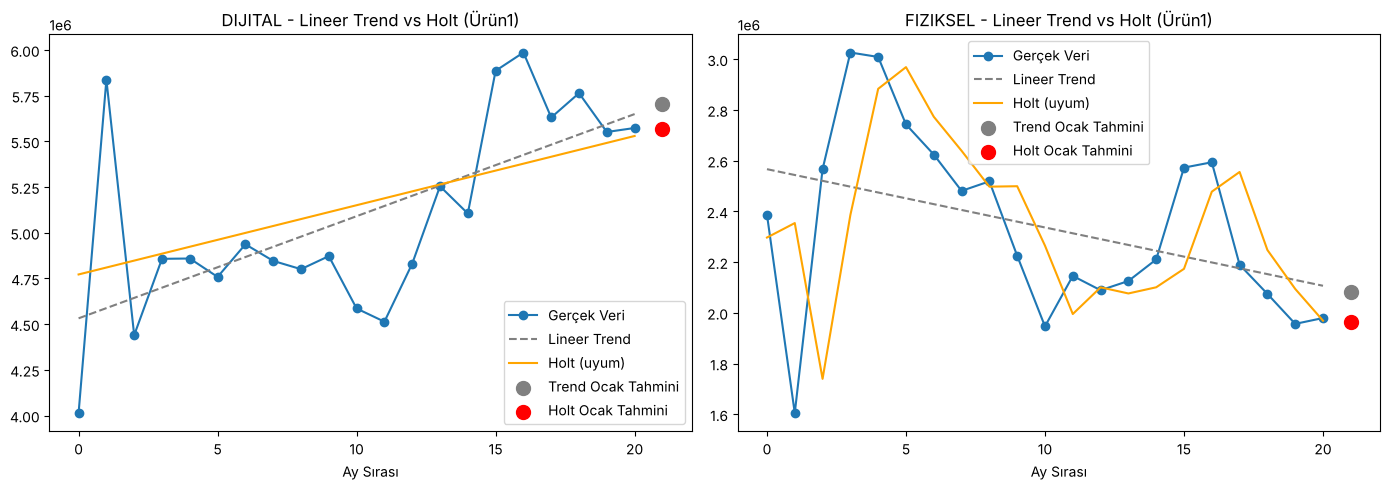

,Trend Tahmini,Holt Tahmini,Alfa,Beta,Naive MAE,Trend MAE,Holt MAE
Kanal,,,,,,,
DIJITAL,5705211,5567328,0.00,0.00,89967,105703,214014
FIZIKSEL,2083649,1962332,0.80,0.00,185961,234338,276848


In [29]:
test_ay = 3
sonuclar = []

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for i, kanal in enumerate(['DIJITAL', 'FIZIKSEL']):
    seri = aylik_kanal_adet[kanal].values
    x = np.arange(len(seri))

    egim, kesisim = np.polyfit(x, seri, 1)
    trend_tahmin = egim * len(seri) + kesisim

    holt = ExponentialSmoothing(seri, trend='add', seasonal=None).fit()
    holt_ocak = holt.forecast(1)[0]

    egitim = seri[:-test_ay]
    test = seri[-test_ay:]
    x_egitim = np.arange(len(egitim))
    x_test = np.arange(len(egitim), len(seri))

    e_egim, e_kesisim = np.polyfit(x_egitim, egitim, 1)
    trend_bt = e_egim * x_test + e_kesisim
    holt_bt = ExponentialSmoothing(egitim, trend='add', seasonal=None).fit().forecast(test_ay)
    naive_bt = np.repeat(egitim[-1], test_ay)

    sonuclar.append({
        'Kanal': kanal,
        'Trend Tahmini': round(trend_tahmin),
        'Holt Tahmini': round(holt_ocak),
        'Alfa': round(holt.params['smoothing_level'], 2),
        'Beta': round(holt.params['smoothing_trend'], 2),
        'Naive MAE': round(np.mean(np.abs(test - naive_bt))),
        'Trend MAE': round(np.mean(np.abs(test - trend_bt))),
        'Holt MAE': round(np.mean(np.abs(test - holt_bt)))
    })

    axes[i].plot(x, seri, marker='o', label='Gerçek Veri')
    axes[i].plot(x, egim * x + kesisim, '--', color='gray', label='Lineer Trend')
    axes[i].plot(x, holt.fittedvalues, color='orange', label='Holt (uyum)')
    axes[i].scatter([len(seri)], [trend_tahmin], color='gray', s=100, zorder=5, label='Trend Ocak Tahmini')
    axes[i].scatter([len(seri)], [holt_ocak], color='red', s=100, zorder=5, label='Holt Ocak Tahmini')
    axes[i].set_title(f'{kanal} - Lineer Trend vs Holt (Ürün1)')
    axes[i].set_xlabel('Ay Sırası')
    axes[i].legend()

plt.tight_layout()
plt.savefig(GORSEL + 'tahmin_2023ocak_urun1.png')
plt.show()

pd.DataFrame(sonuclar).set_index('Kanal')

**Backtest yorumu:** Son 3 ayda en düşük hatayı naive tahmin veriyor; lineer trend ve Holt daha kötü. Yani 21 aylık seride modeller son dönemdeki seviye değişimini yakalamakta zorlanıyor. Bu yüzden tek bir sayı yerine yöntemlerin verdiği **aralık** raporlandı: Dijital için yöntemler birbirine çok yakın (yüksek güven), fiziksel için ~1.75–2.1 milyon arası (orta güven).

### 8.2 Çapraz ürün (Ürün2)

In [30]:
aylik_kanal_capraz = capraz.groupby(['TARIH','KANAL'])['ÇAPRAZ ÜRÜN ADET'].sum().unstack()

print("=== 2023 Ocak Ürün2 Satış Adedi Tahmini ===")
tahmin_tablosu(aylik_kanal_capraz)

=== 2023 Ocak Ürün2 Satış Adedi Tahmini ===


,Lineer Trend,Holt,YoY Büyüme
Kanal,,,
DIJITAL,42040,48670,68389
FIZIKSEL,149456,140686,129154


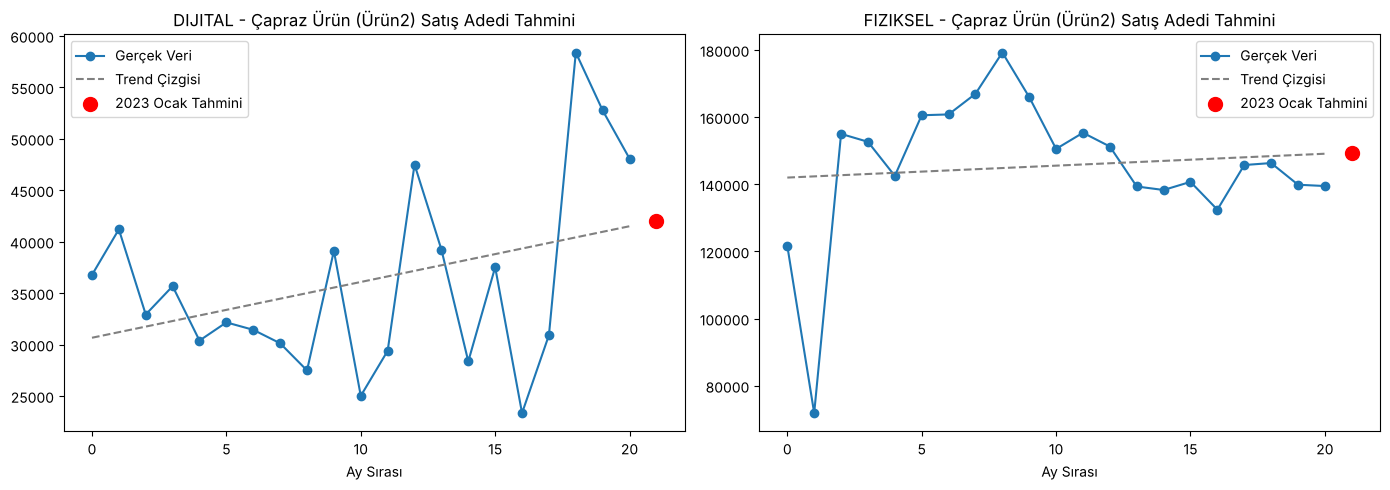

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(14,5))

for i, kanal in enumerate(['DIJITAL', 'FIZIKSEL']):
    seri = aylik_kanal_capraz[kanal]
    x = np.arange(len(seri))
    egim, kesisim = np.polyfit(x, seri.values, 1)
    tahmin_y = egim * len(seri) + kesisim

    axes[i].plot(x, seri.values, marker='o', label='Gerçek Veri')
    axes[i].plot(x, egim*x+kesisim, '--', color='gray', label='Trend Çizgisi')
    axes[i].scatter([len(seri)], [tahmin_y], color='red', s=100, zorder=5, label='2023 Ocak Tahmini')
    axes[i].set_title(f'{kanal} - Çapraz Ürün (Ürün2) Satış Adedi Tahmini')
    axes[i].set_xlabel('Ay Sırası')
    axes[i].legend()

plt.tight_layout()
plt.savefig(GORSEL + 'tahmin_2023ocak_urun2.png')
plt.show()

**Not:** Dijital kanalda Ürün2 satışları son iki ayda (Ekim–Kasım 2022) ani bir sıçrama yapıyor. Bu yüzden yöntemler arasındaki fark büyük ve dijital Ürün2 tahmini düşük güvenle verilmeli. Fiziksel kanal tahminleri daha tutarlı.

## Sonuç ve öneriler

1. **Satış süreci revizyonu:** Fiziksel kanaldaki yüksek çapraz ürün iptali için satış script'i ve eğitim programı gözden geçirilmeli. 6–45 gün içindeki iptallerin yoğunluğu, ürünün satış anında doğru anlatılmadığına işaret ediyor.
2. **Bölgesel odaklanma:** En yüksek iptal oranına sahip İstanbul/Trakya bölgesinin satış ekibi ve yönetim pratiği öncelikli olarak incelenmeli.
3. **Komisyon yapısı:** Satış komisyonu sadece satış anına değil, satışın kalıcılığına (45 gün sonra hâlâ aktif mi) göre de belirlenmeli. Bu, agresif satışı caydırır.
4. **Reel büyüme metrikleri:** Raporlamada nominal cironun yanında enflasyondan bağımsız satış adedi de takip edilmeli; fiziksel kanalda ciro artışı adet düşüşünü gizliyor.
5. **Risk dağıtımı:** Ciro az sayıda yıldız şubeye bağımlı. Orta segment şubelere yatırım yaparak bu risk azaltılabilir.